# I - Chargement et premier profilage
Objectif : comprendre la structure du dataset avant tout nettoyage.

In [1]:
# Doit être exécuté AVANT l'import de scikit-learn :
# évite une fuite de mémoire de KMeans sur Windows (MKL)
import os
os.environ["OMP_NUM_THREADS"] = "7"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/marketing_campaign.csv", sep="\t")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [3]:
print(df.shape)
df.info()

(2240, 29)
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [5]:
df.isna().sum()[df.isna().sum() > 0]

Income    24
dtype: int64

In [6]:
display(df.describe().T)
df.nunique().sort_values()

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


Z_Revenue                 1
Z_CostContact             1
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
Complain                  2
AcceptedCmp2              2
Response                  2
Teenhome                  3
Kidhome                   3
Education                 5
Marital_Status            8
NumStorePurchases        14
NumCatalogPurchases      14
NumDealsPurchases        15
NumWebPurchases          15
NumWebVisitsMonth        16
Year_Birth               59
Recency                 100
MntFruits               158
MntSweetProducts        177
MntFishProducts         182
MntGoldProds            213
MntMeatProducts         558
Dt_Customer             663
MntWines                776
Income                 1974
ID                     2240
dtype: int64

In [7]:
print(df["Education"].value_counts())
print(df["Marital_Status"].value_counts())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


### Conclusions
- Le dataset contient **2 240 clients** et **29 variables** : profil socio-démographique, dépenses par catégorie de produits sur 2 ans, canaux d'achat et réponses à 6 campagnes marketing.
- Le fichier est séparé par des tabulations (`sep="\t"`).
- **Problèmes de qualité identifiés :**
  - `Income` contient 24 valeurs manquantes (~1 %).
  - `ID` est un identifiant sans valeur prédictive ; `Z_CostContact` et `Z_Revenue` sont constantes.
  - `Dt_Customer` est lue comme du texte au lieu d'une date.
  - Valeurs aberrantes : années de naissance antérieures à 1900, un revenu de 666 666.
  - `Marital_Status` contient des catégories rares ou incohérentes (« YOLO », « Absurd »).
- Il n'y a **pas de variable cible** : il s'agit d'un problème non supervisé. La qualité des segments sera évaluée par des métriques internes et par leur utilité métier.

# II - Nettoyage des données
Objectif : produire un dataset propre (sans valeurs manquantes, sans aberrations, catégories simplifiées) prêt pour le feature engineering.

## 1. Suppression des colonnes inutiles
- `ID` : identifiant sans information comportementale.
- `Z_CostContact`, `Z_Revenue` : colonnes constantes (une seule valeur unique).

In [8]:
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])

## 2. Valeurs manquantes de `Income`
Environ 1 % de valeurs manquantes. Imputation par la médiane, car la moyenne est tirée vers le haut par des revenus extrêmes.

In [9]:
print("Manquants avant :", df["Income"].isna().sum())
df["Income"] = df["Income"].fillna(df["Income"].median())
print("Manquants après :", df["Income"].isna().sum())

Manquants avant : 24
Manquants après : 0


## 3. Conversion de `Dt_Customer`
On vérifie d'abord si le premier nombre peut dépasser 12 (ce serait alors le jour).

In [10]:
premier_nombre = df["Dt_Customer"].str.split("-").str[0].astype(int)
print("Max du premier nombre :", premier_nombre.max())

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
print(df["Dt_Customer"].min(), "→", df["Dt_Customer"].max())

Max du premier nombre : 31
2012-07-30 00:00:00 → 2014-06-29 00:00:00


## 4. Valeurs aberrantes
- `Year_Birth` ≤ 1900 : âges supérieurs à 110 ans, probables erreurs de saisie.
- `Income` extrême (666 666) : très éloigné de tous les autres clients.

In [11]:
print("Avant :", df.shape)
print(df.loc[df["Year_Birth"] <= 1900, "Year_Birth"].tolist())
print(df["Income"].sort_values(ascending=False).head(5).tolist())

df = df[(df["Year_Birth"] > 1900) & (df["Income"] < 600_000)]
print("Après :", df.shape)

Avant : (2240, 26)
[1900, 1893, 1899]
[666666.0, 162397.0, 160803.0, 157733.0, 157243.0]
Après : (2236, 26)


## 5. Simplification des catégories
- `Marital_Status` → En couple / Seul (ce qui compte pour les habitudes d'achat ; élimine aussi les catégories farfelues).
- `Education` → 3 niveaux cohérents.

In [12]:
df["Marital_Status"] = df["Marital_Status"].replace({
    "Married": "En couple", "Together": "En couple",
    "Single": "Seul", "Divorced": "Seul", "Widow": "Seul",
    "Alone": "Seul", "Absurd": "Seul", "YOLO": "Seul",
})

df["Education"] = df["Education"].replace({
    "Basic": "Premier cycle", "2n Cycle": "Premier cycle",
    "Graduation": "Licence",
    "Master": "Postgrad", "PhD": "Postgrad",
})

print(df["Marital_Status"].value_counts())
print(df["Education"].value_counts())

Marital_Status
En couple    1442
Seul          794
Name: count, dtype: int64
Education
Licence          1126
Postgrad          855
Premier cycle     255
Name: count, dtype: int64


## 6. Vérification finale et sauvegarde

In [13]:
print("Forme finale :", df.shape)
print("Valeurs manquantes :", df.isna().sum().sum())

# df.to_csv("../data/clients_nettoyes.csv", index=False)

Forme finale : (2236, 26)
Valeurs manquantes : 0


### Conclusions
- Colonnes `ID`, `Z_CostContact` et `Z_Revenue` supprimées.
- Valeurs manquantes de `Income` imputées par la **médiane**, robuste aux valeurs extrêmes (la suppression des ~1 % de lignes était aussi défendable).
- `Dt_Customer` convertie en date (format jour-mois-année).
- 4 clients aberrants retirés (3 nés en 1900 ou avant, 1 revenu de 666 666), car ils fausseraient les distances et pourraient former un cluster à eux seuls.
- `Marital_Status` regroupé en « En couple » / « Seul » et `Education` en 3 niveaux, pour éliminer les catégories rares qui ajouteraient du bruit.
- **Dataset final : 2 236 clients, 26 variables, aucune valeur manquante.**

# III - Feature engineering

In [14]:
# Date de référence : la dernière inscription du dataset (les données datent de 2014)
date_ref = df["Dt_Customer"].max()

# Âge au moment de la collecte des données
df["Age"] = date_ref.year - df["Year_Birth"]

# Ancienneté client, en mois
df["Anciennete_mois"] = (date_ref - df["Dt_Customer"]).dt.days // 30

# Dépenses totales sur 2 ans, toutes catégories
cols_depenses = ["MntWines", "MntFruits", "MntMeatProducts",
                 "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["Depenses_totales"] = df[cols_depenses].sum(axis=1)

# Nombre total d'achats, tous canaux confondus
cols_achats = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df["Achats_totaux"] = df[cols_achats].sum(axis=1)

# Composition du foyer
df["Enfants"] = df["Kidhome"] + df["Teenhome"]
df["Taille_foyer"] = df["Enfants"] + df["Marital_Status"].map({"En couple": 2, "Seul": 1})
df["Est_parent"] = (df["Enfants"] > 0).astype(int)

# Sensibilité au marketing : nombre de campagnes acceptées
cols_campagnes = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
                  "AcceptedCmp4", "AcceptedCmp5", "Response"]
df["Campagnes_acceptees"] = df[cols_campagnes].sum(axis=1)

df[["Age", "Anciennete_mois", "Depenses_totales", "Achats_totaux",
    "Enfants", "Taille_foyer", "Campagnes_acceptees"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2236.0,45.101968,11.703281,18.0,37.0,44.0,55.0,74.0
Anciennete_mois,2236.0,11.321109,6.730526,0.0,6.0,11.0,17.0,23.0
Depenses_totales,2236.0,605.986583,601.865156,5.0,69.0,396.5,1045.5,2525.0
Achats_totaux,2236.0,12.546512,7.206577,0.0,6.0,12.0,18.0,32.0
Enfants,2236.0,0.950805,0.752204,0.0,0.0,1.0,1.0,3.0
Taille_foyer,2236.0,2.595707,0.907468,1.0,2.0,3.0,3.0,5.0
Campagnes_acceptees,2236.0,0.447227,0.891113,0.0,0.0,0.0,1.0,5.0


### Conclusions
- Nouvelles variables créées : `Age`, `Anciennete_mois`, `Depenses_totales`, `Achats_totaux`, `Enfants`, `Taille_foyer`, `Est_parent`, `Campagnes_acceptees`.
- L'âge et l'ancienneté sont calculés par rapport à la date des données ([année de date_ref]) et non à aujourd'hui, pour décrire le client au moment de ses achats.
- **Choix de modélisation clé :** le clustering est fait uniquement sur les **variables comportementales** (ce que le client achète, comment, et son engagement). Les variables socio-démographiques sont réservées au profilage des segments, pour trois raisons :
  1. des segments comportementaux se traduisent directement en actions marketing ;
  2. on évite des segments dominés par le revenu ou l'âge ;
  3. constater après coup que les segments diffèrent démographiquement valide leur pertinence de façon indépendante.
- `Depenses_totales` et `Achats_totaux` sont exclues du clustering : ce sont des sommes d'autres variables, elles doubleraient le poids de cette information dans les distances. Elles serviront au profilage.
- **13 variables retenues pour le clustering** : les 6 `Mnt*`, les 4 `Num*Purchases`, `NumWebVisitsMonth`, `Recency` et `Campagnes_acceptees`.

# IV - Analyse exploratoire

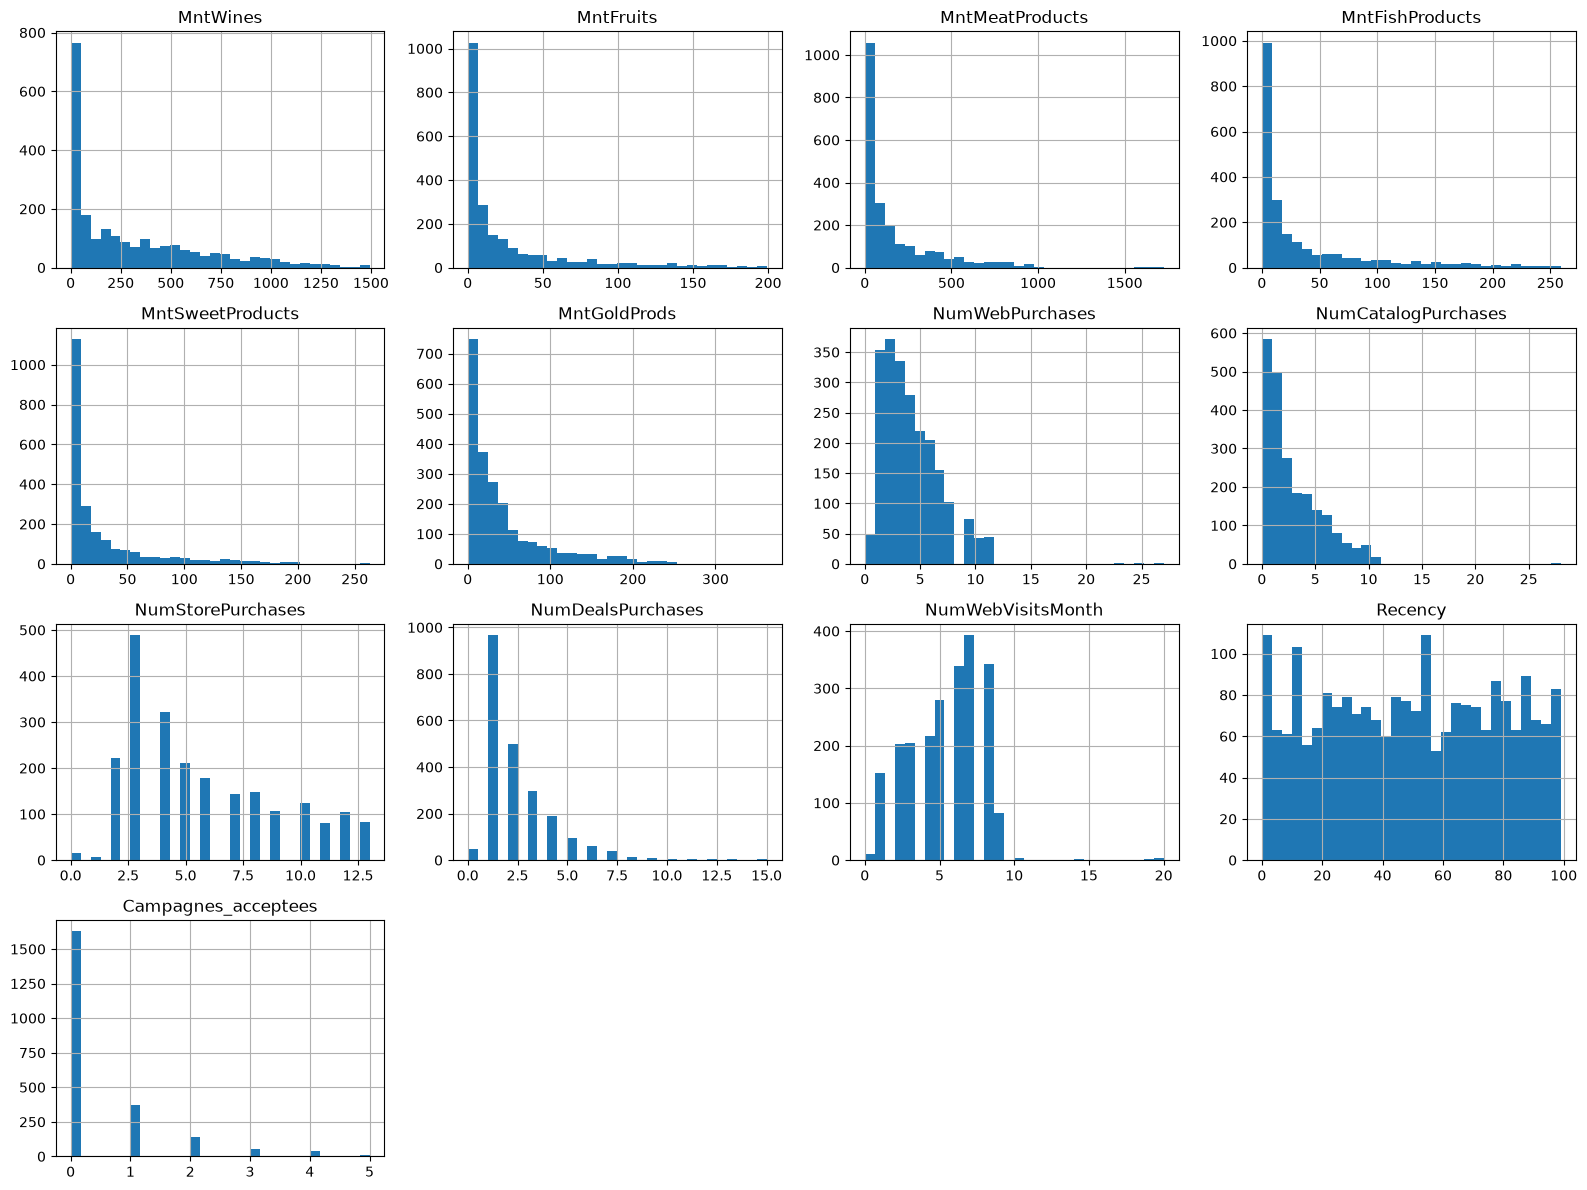

Campagnes_acceptees    2.439585
NumDealsPurchases      2.418461
MntSweetProducts       2.135674
MntFruits              2.104241
MntMeatProducts        2.085282
MntFishProducts        1.919970
MntGoldProds           1.885136
NumCatalogPurchases    1.881437
NumWebPurchases        1.381134
MntWines               1.176036
NumStorePurchases      0.700138
NumWebVisitsMonth      0.207904
Recency               -0.004299
dtype: float64


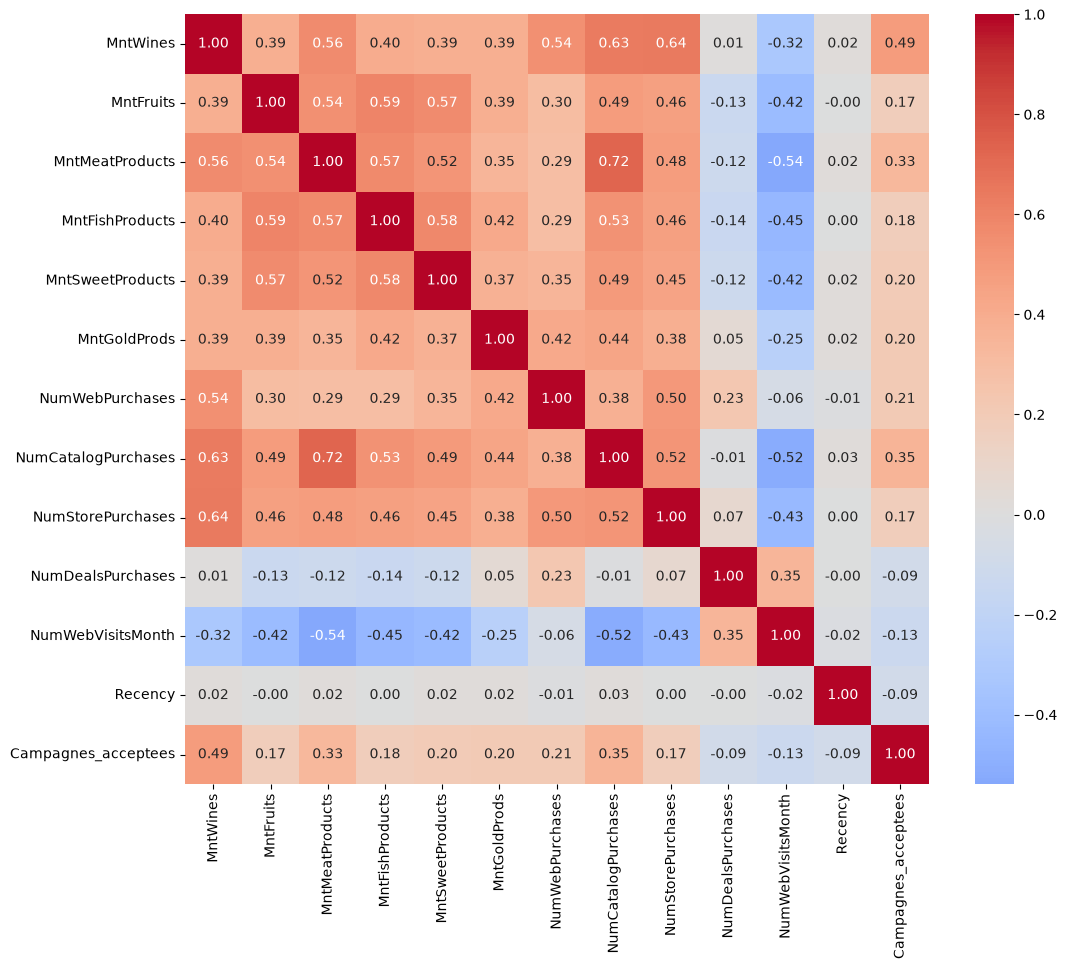

In [15]:
features_clustering = [
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds",
    "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
    "NumDealsPurchases", "NumWebVisitsMonth",
    "Recency", "Campagnes_acceptees",
]
X = df[features_clustering]

# Distributions
X.hist(bins=30, figsize=(16, 12))
plt.tight_layout()
plt.show()

# Asymétrie de chaque variable (skewness)
print(X.skew().sort_values(ascending=False))

# Corrélations
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

### Conclusions
- **Distributions :** les dépenses (`Mnt*`) et plusieurs variables d'achat sont fortement **asymétriques à droite** (skew > 1) : la majorité des clients dépense peu, une minorité dépense beaucoup.
  - Conséquence : KMeans minimise des distances au carré, donc les gros dépensiers domineraient le calcul et la masse des petits clients serait mal différenciée. La standardisation seule ne corrige pas la forme d'une distribution → une transformation logarithmique est nécessaire.
- **Corrélations :**
  - Vin, viande et achats par catalogue/en magasin sont fortement liés : profil probable de clients aisés, acheteurs de produits premium.
  - Fruits, poisson et sucreries sont liés entre eux : panier alimentaire distinct.
  - Les dépenses sont globalement corrélées positivement : un facteur commun de **niveau de dépense** se dégage, que la PCA devrait faire ressortir comme premier axe.
  - `NumWebVisitsMonth` est **négativement corrélée** aux dépenses (environ -0.54 avec `MntMeatProducts` et -0.52 avec `NumCatalogPurchases`) : les clients qui visitent le plus le site sont ceux qui dépensent le moins. Hypothèse : des clients au budget plus serré qui comparent et cherchent les promotions (à confirmer avec la corrélation positive entre `NumWebVisitsMonth` et `NumDealsPurchases`). Pour le marketing : beaucoup de trafic web ne signifie pas beaucoup de chiffre d'affaires.

# V - Transformation et mise à l’échelle

In [16]:
from sklearn.preprocessing import StandardScaler

X = df[features_clustering].copy()

# Variables fortement asymétriques (skew > 1)
skew = X.skew()
cols_log = skew[skew > 1].index.tolist()
print("Variables transformées en log :", cols_log)

# Transformation log1p : log(1 + x)
X[cols_log] = np.log1p(X[cols_log])
print(X.skew().sort_values(ascending=False))

# Standardisation : moyenne 0, écart-type 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features_clustering, index=X.index)
X_scaled.describe().T[["mean", "std"]]

Variables transformées en log : ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumWebPurchases', 'NumCatalogPurchases', 'NumDealsPurchases', 'Campagnes_acceptees']
Campagnes_acceptees    1.555240
NumStorePurchases      0.700138
NumDealsPurchases      0.665689
NumWebVisitsMonth      0.207904
NumCatalogPurchases    0.131493
MntSweetProducts       0.084655
MntFruits              0.083568
Recency               -0.004299
MntFishProducts       -0.052378
MntMeatProducts       -0.084483
NumWebPurchases       -0.265821
MntGoldProds          -0.343379
MntWines              -0.550316
dtype: float64


,mean,std
MntWines,-1.350540e-17,1.000224
MntFruits,-1.112209e-17,1.000224
MntMeatProducts,4.162840e-16,1.000224
MntFishProducts,5.561046e-17,1.000224
MntSweetProducts,4.448836e-17,1.000224
MntGoldProds,1.112209e-16,1.000224
NumWebPurchases,3.352516e-16,1.000224
NumCatalogPurchases,-2.240307e-16,1.000224
NumStorePurchases,-1.322734e-16,1.000224
NumDealsPurchases,1.684202e-16,1.000224


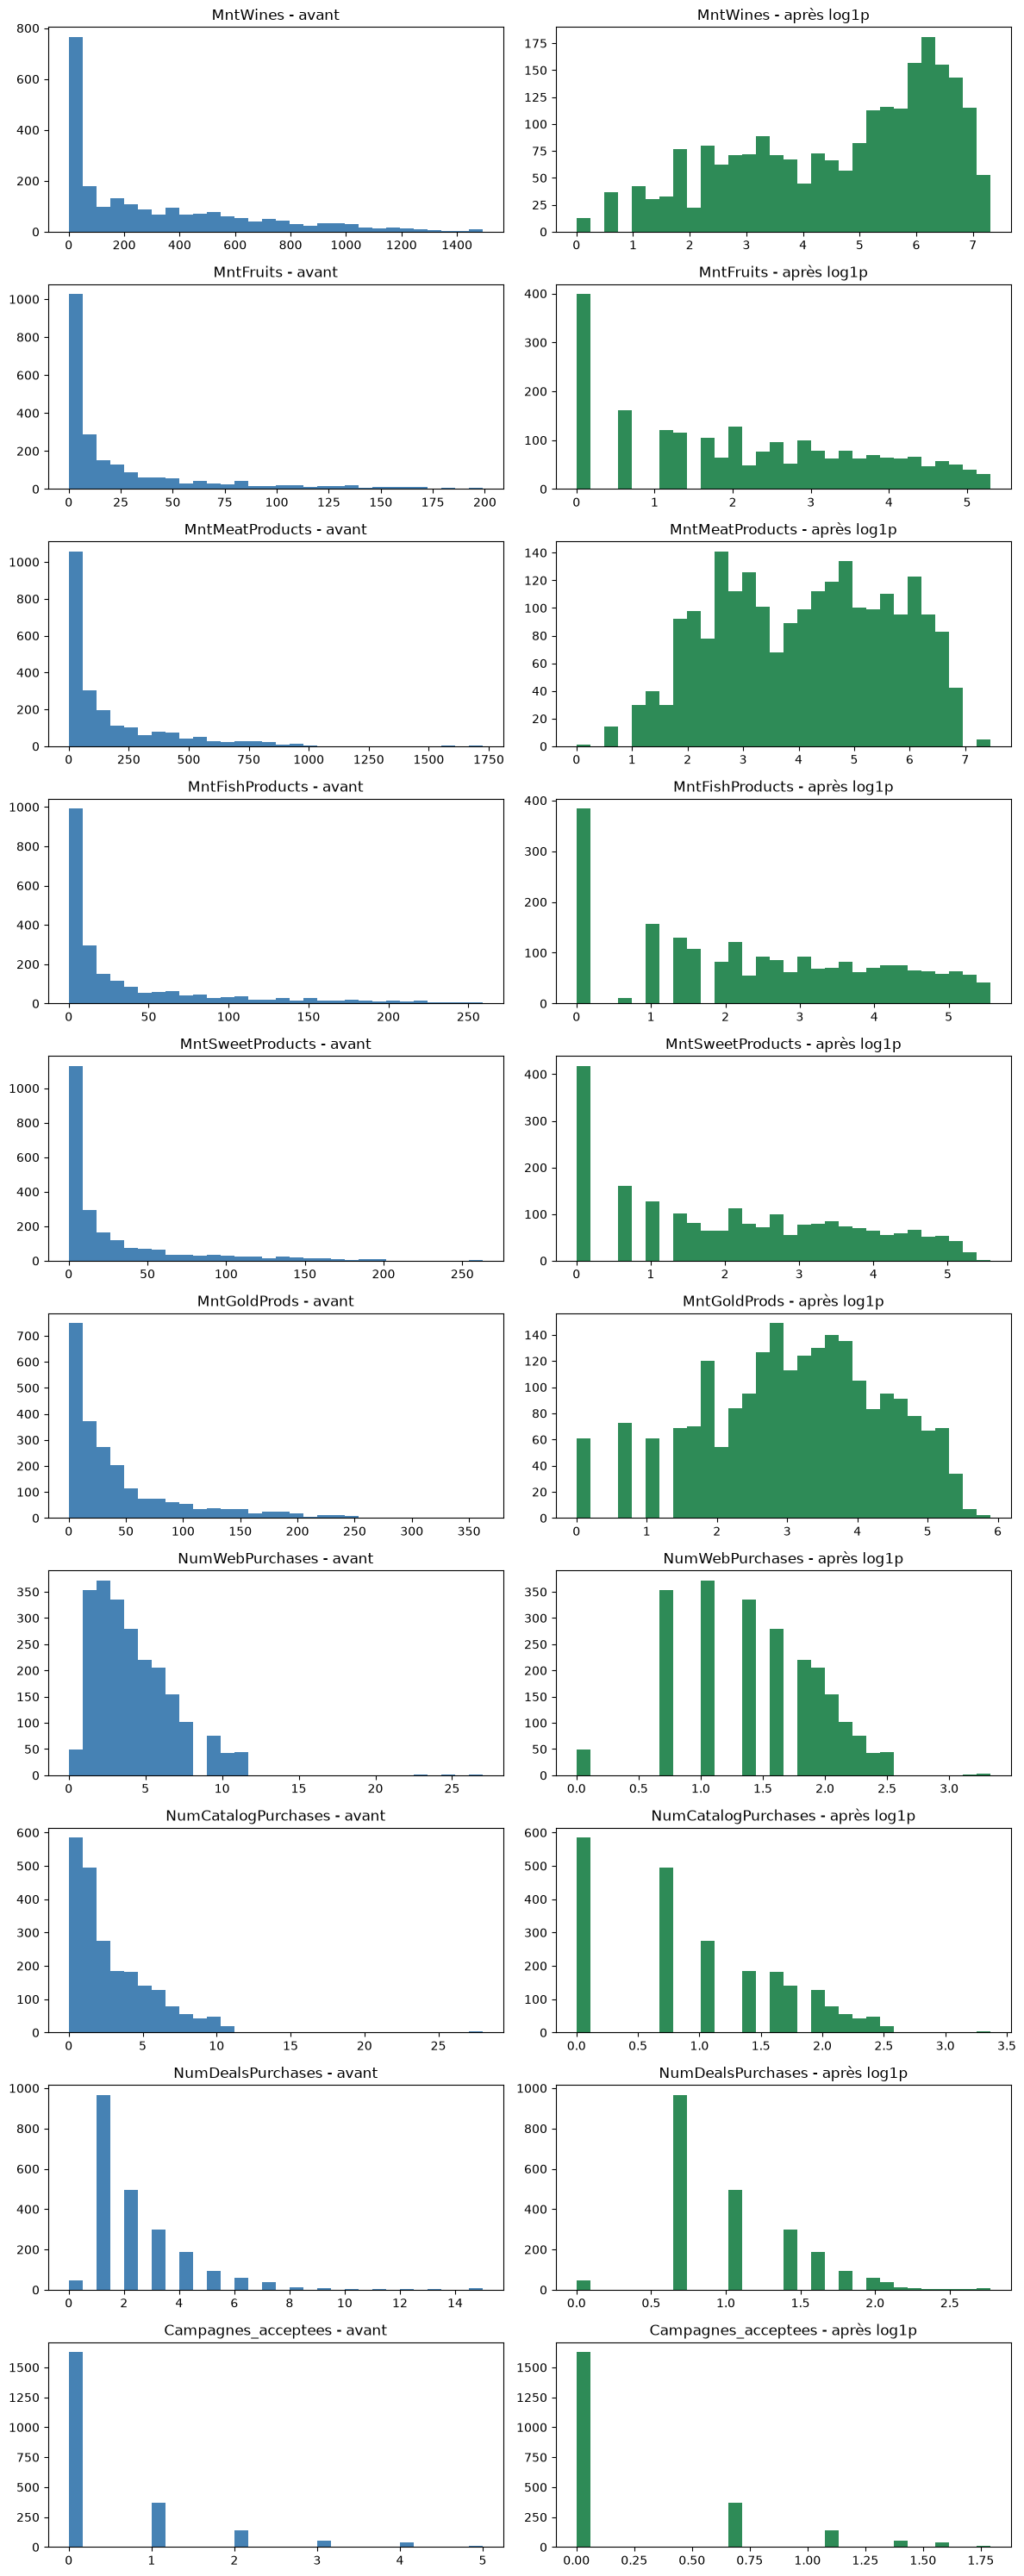

In [17]:
fig, axes = plt.subplots(len(cols_log), 2, figsize=(12, 3 * len(cols_log)))

for i, col in enumerate(cols_log):
    axes[i, 0].hist(df[col], bins=30, color="steelblue")
    axes[i, 0].set_title(f"{col} - avant")
    axes[i, 1].hist(X[col], bins=30, color="seagreen")
    axes[i, 1].set_title(f"{col} - après log1p")

plt.tight_layout()
plt.show()

### Conclusions 
- **Transformation logarithmique** appliquée aux variables fortement asymétriques (skew > 1) : [liste affichée par `cols_log`].
  - On utilise `log1p` (log(1 + x)) car les dépenses contiennent des 0 : `log(0)` donne `-inf`, alors que `log1p(0) = 0`.
  - Après transformation, le skew de ces variables passe de [plage avant] à [plage après] : les distributions sont nettement plus symétriques, les gros dépensiers ne dominent plus les distances.
- Les variables déjà à peu près symétriques (`Recency`, de distribution quasi uniforme, [autres]) ne sont pas transformées : un log y créerait une asymétrie artificielle.
- **Standardisation** (`StandardScaler`) ensuite appliquée à toutes les variables : moyenne 0, écart-type 1, pour qu'aucune ne domine les distances à cause de son unité.
- L'ordre compte : on transforme d'abord la *forme* (log), puis on harmonise l'*échelle* (standardisation).
- Résultat : `X_scaled`, matrice de 2 236 clients × 13 variables, prête pour la PCA et le clustering.

# VI - PCA

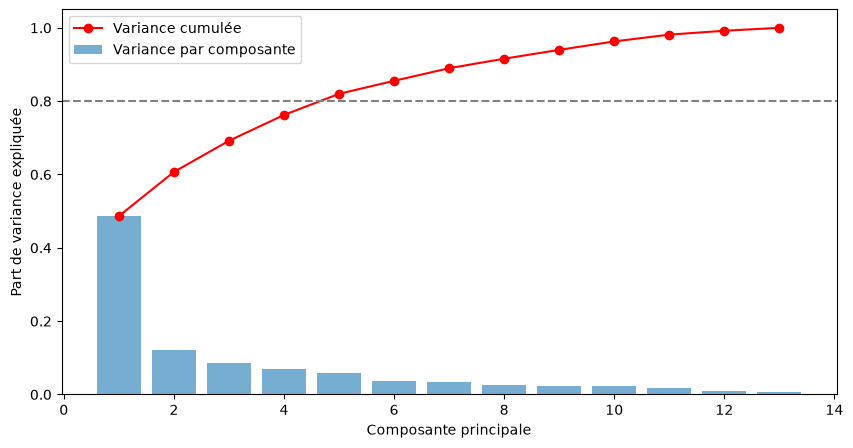

PC1 : 48.7%  (cumulé : 48.7%)
PC2 : 12.0%  (cumulé : 60.7%)
PC3 : 8.5%  (cumulé : 69.2%)
PC4 : 7.0%  (cumulé : 76.2%)
PC5 : 5.8%  (cumulé : 82.0%)
PC6 : 3.6%  (cumulé : 85.5%)
PC7 : 3.4%  (cumulé : 89.0%)
PC8 : 2.6%  (cumulé : 91.6%)
PC9 : 2.4%  (cumulé : 94.0%)
PC10 : 2.3%  (cumulé : 96.3%)
PC11 : 1.8%  (cumulé : 98.1%)
PC12 : 1.1%  (cumulé : 99.2%)
PC13 : 0.8%  (cumulé : 100.0%)


In [18]:
from sklearn.decomposition import PCA

# PCA complète, pour voir combien d'information porte chaque axe
pca = PCA()
pca.fit(X_scaled)

variance = pca.explained_variance_ratio_
variance_cumulee = np.cumsum(variance)

plt.figure(figsize=(10, 5))
plt.bar(range(1, len(variance) + 1), variance, alpha=0.6, label="Variance par composante")
plt.plot(range(1, len(variance) + 1), variance_cumulee, marker="o", color="red", label="Variance cumulée")
plt.axhline(0.8, linestyle="--", color="gray")
plt.xlabel("Composante principale")
plt.ylabel("Part de variance expliquée")
plt.legend()
plt.show()

for i, (v, vc) in enumerate(zip(variance, variance_cumulee), start=1):
    print(f"PC{i} : {v:.1%}  (cumulé : {vc:.1%})")

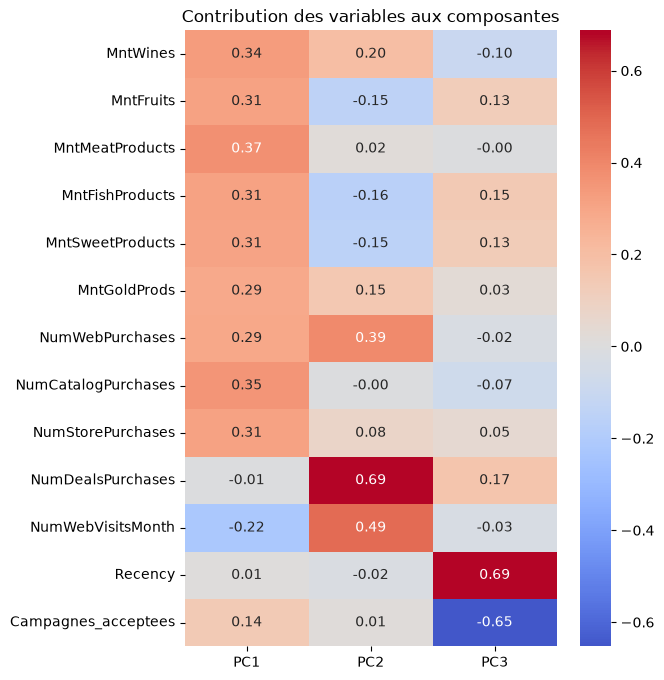

In [19]:
# Contribution de chaque variable aux 3 premières composantes (les "loadings")
loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=["PC1", "PC2", "PC3"],
    index=features_clustering,
)
plt.figure(figsize=(6, 8))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Contribution des variables aux composantes")
plt.show()

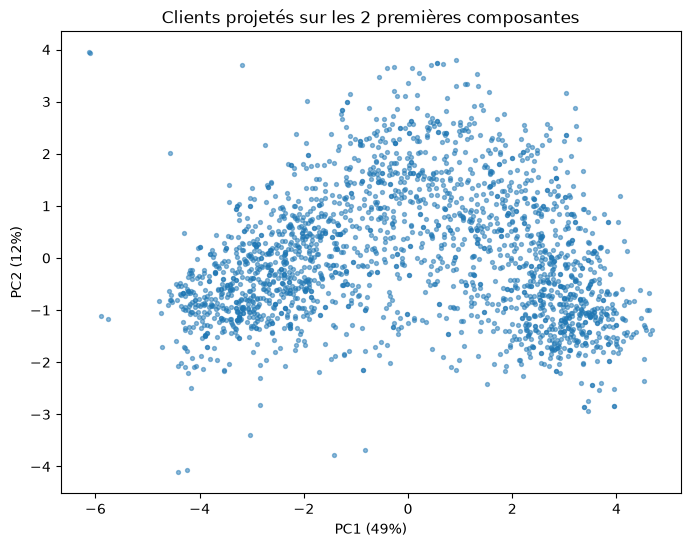

In [20]:
# Projection des clients sur les 2 premiers axes
X_pca = pca.transform(X_scaled)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=8, alpha=0.5)
plt.xlabel(f"PC1 ({variance[0]:.0%})")
plt.ylabel(f"PC2 ({variance[1]:.0%})")
plt.title("Clients projetés sur les 2 premières composantes")
plt.show()

### Conclusions
- **Variance expliquée :** PC1 capte 48,7 % de l'information, PC2 12 %, PC3 8,5 %. Il faut **5 composantes pour atteindre 82 %**. La forte part de PC1 confirme les corrélations de l'analyse exploratoire : un facteur commun domine les données.
- **Interprétation des axes (loadings) :**
  - **PC1 - Niveau d'achat :** toutes les dépenses et tous les achats par canal pèsent positivement (~0,3), les visites web négativement (-0,22). Distingue les gros acheteurs des petits.
  - **PC2 - Chasse aux promotions en ligne :** dominé par `NumDealsPurchases` (0,69), `NumWebVisitsMonth` (0,49) et `NumWebPurchases` (0,39).
  - **PC3 - Désengagement :** `Recency` (+0,69) s'oppose à `Campagnes_acceptees` (-0,65) ; distingue les clients inactifs et peu réceptifs des clients récents et réactifs.
- **Projection PC1 × PC2 :** nuage **continu en forme d'arche**, sans groupes nettement séparés. Les acheteurs moyens sont les plus friands de promotions ; les petits et les gros acheteurs en utilisent peu. Deux zones plus denses apparaissent aux extrémités, et quelques clients atypiques sont isolés.
- **Implication :** la segmentation découpera un continuum plutôt que de révéler des groupes naturellement séparés. KMeans et la CAH devraient fournir des segments exploitables ; DBSCAN risque de peiner. L'interprétation métier sera décisive.

# VII - KMeans

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pca5 = PCA(n_components=5, random_state=42)
X_pca5 = pca5.fit_transform(X_scaled)
print("Variance conservée :", pca5.explained_variance_ratio_.sum().round(3))

Variance conservée : 0.82


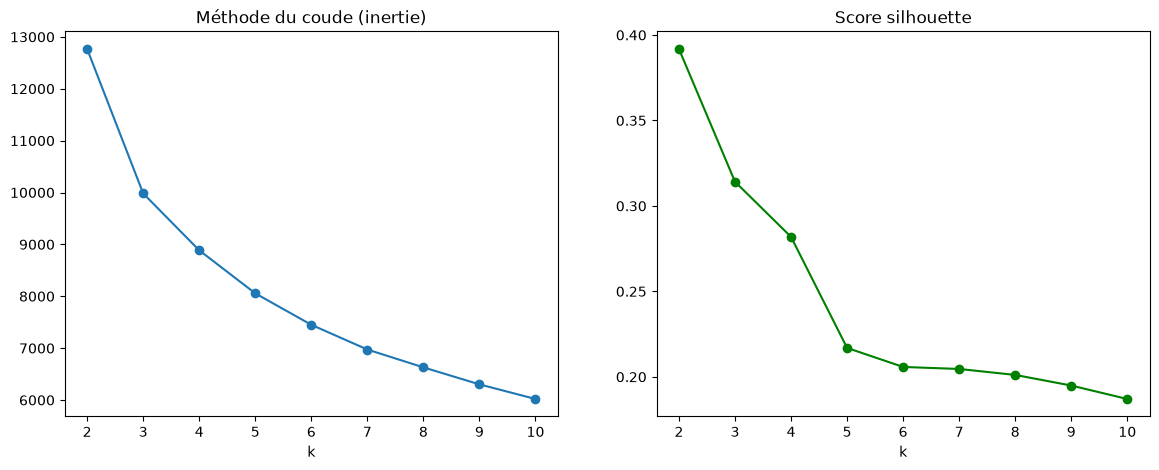

k=2 : silhouette = 0.392
k=3 : silhouette = 0.314
k=4 : silhouette = 0.282
k=5 : silhouette = 0.217
k=6 : silhouette = 0.206
k=7 : silhouette = 0.205
k=8 : silhouette = 0.201
k=9 : silhouette = 0.195
k=10 : silhouette = 0.187


In [22]:
# Tester plusieurs valeurs de k
ks = range(2, 11)
inerties, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_pca5)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca5, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ks, inerties, marker="o")
axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("k")
axes[1].plot(ks, silhouettes, marker="o", color="green")
axes[1].set_title("Score silhouette")
axes[1].set_xlabel("k")
plt.show()

for k, s in zip(ks, silhouettes):
    print(f"k={k} : silhouette = {s:.3f}")

Segment_KMeans
0    838
1    309
2    522
3    567
Name: count, dtype: int64


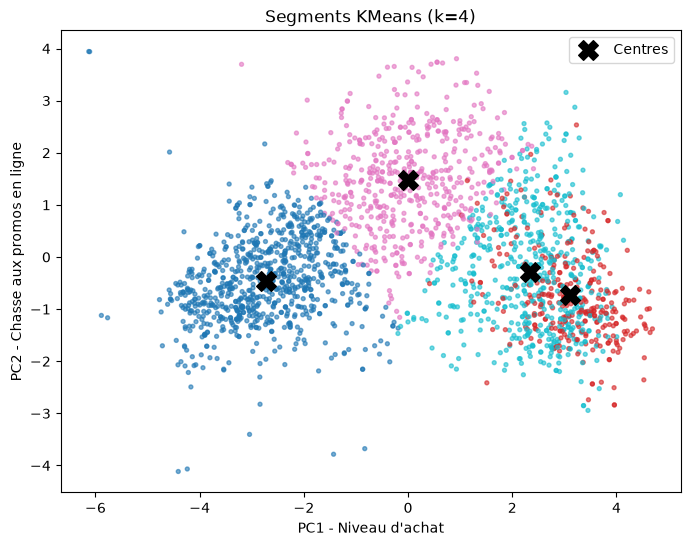

In [23]:
# Entrainer le modèle final avec la valeur de k choisie
K = 4  # à ajuster selon les courbes
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["Segment_KMeans"] = kmeans.fit_predict(X_pca5)

print(df["Segment_KMeans"].value_counts().sort_index())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca5[:, 0], X_pca5[:, 1], c=df["Segment_KMeans"], cmap="tab10", s=8, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="black", marker="X", s=200, label="Centres")
plt.xlabel("PC1 - Niveau d'achat")
plt.ylabel("PC2 - Chasse aux promos en ligne")
plt.legend()
plt.title(f"Segments KMeans (k={K})")
plt.show()

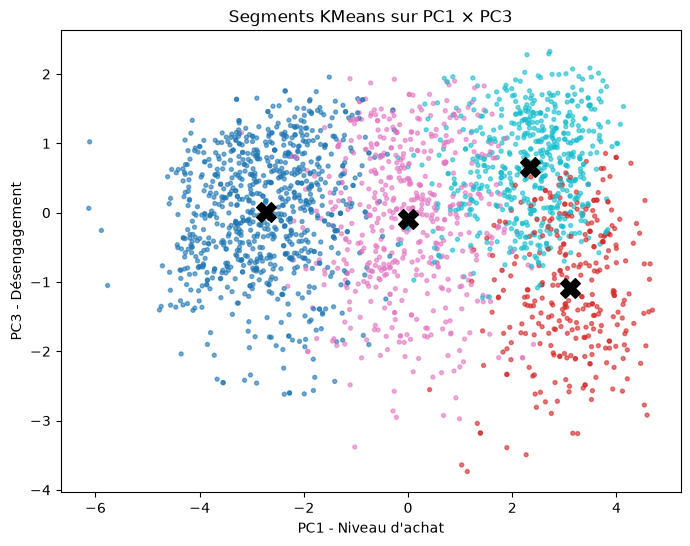

,Depenses_totales,NumDealsPurchases,NumWebVisitsMonth,Recency,Campagnes_acceptees
Segment_KMeans,,,,,
0,69.5,1.7,6.4,48.6,0.1
1,1519.0,1.1,3.2,47.5,2.0
2,497.9,4.1,6.8,48.5,0.5
3,1000.9,2.2,3.6,51.3,0.0


In [24]:
# Projection sur PC1 × PC3
plt.figure(figsize=(8, 6))
plt.scatter(X_pca5[:, 0], X_pca5[:, 2], c=df["Segment_KMeans"], cmap="tab10", s=8, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 2],
            c="black", marker="X", s=200)
plt.xlabel("PC1 - Niveau d'achat")
plt.ylabel("PC3 - Désengagement")
plt.title("Segments KMeans sur PC1 × PC3")
plt.show()

# Moyennes des variables clés par segment, dans leurs unités d'origine
df.groupby("Segment_KMeans")[[
    "Depenses_totales", "NumDealsPurchases", "NumWebVisitsMonth",
    "Recency", "Campagnes_acceptees"
]].mean().round(1)

### Conclusions
- **Données utilisées :** les 5 premières composantes PCA (82 % de la variance), pour éliminer la redondance entre variables de dépense et réduire le bruit.
- **Choix de k = 4 :**
  - le coude de l'inertie se situe autour de 3-4 ;
  - le score silhouette passe de 0,39 (k=2) à 0,28 (k=4), puis **chute à 0,22 à k=5** ;
  - k=2 a le meilleur score mais se réduit à « petits vs gros acheteurs », sans valeur ajoutée pour le marketing. k=4 est le meilleur compromis entre qualité géométrique et actionnabilité.
- **Taille des segments :** équilibrée, de 14 % à 37 % des clients ; aucun segment marginal.
- **Lecture des projections :**
  - sur PC1 × PC2, KMeans découpe l'arche : petits acheteurs à gauche, chasseurs de promos au sommet, gros acheteurs à droite ;
  - deux segments de gros acheteurs se chevauchent sur PC1 × PC2 mais **se séparent sur PC3** : une projection 2D ne montre qu'une partie de la structure.
- **Segments obtenus :**
  - **Segment 0 - Petits acheteurs (37 %)** : ~70 de dépenses, beaucoup de visites web, insensibles aux campagnes.
  - **Segment 2 - Chasseurs de promos (23 %)** : ~500 de dépenses, 4,1 achats en promotion, 6,8 visites web/mois.
  - **Segment 3 - Gros acheteurs autonomes (25 %)** : ~1 000 de dépenses, aucune campagne acceptée.
  - **Segment 1 - Premium engagés (14 %)** : ~1 500 de dépenses, 2 campagnes acceptées en moyenne.
- **Observations clés :**
  - `Recency` est quasi identique dans tous les segments (47 à 51 jours) : elle ne contribue pas à la segmentation.
  - Les campagnes actuelles ne touchent réellement que le segment premium ; le segment 3, à forte valeur, y est totalement imperméable.

# VIII - La CAH

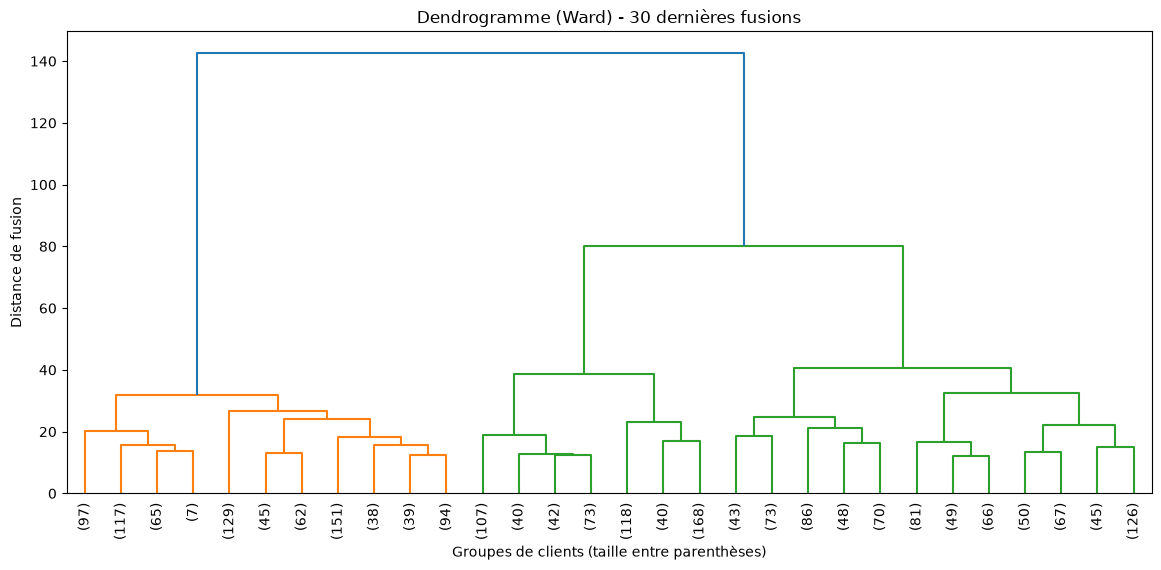

In [25]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# Arbre de fusion avec la méthode de Ward
Z = linkage(X_pca5, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogramme (Ward) - 30 dernières fusions")
plt.xlabel("Groupes de clients (taille entre parenthèses)")
plt.ylabel("Distance de fusion")
plt.show()

In [26]:
# Modèle CAH avec 4 segments, pour comparer avec KMeans
cah = AgglomerativeClustering(n_clusters=4, linkage="ward")
df["Segment_CAH"] = cah.fit_predict(X_pca5)

print(df["Segment_CAH"].value_counts().sort_index())
print("Silhouette CAH :", round(silhouette_score(X_pca5, df["Segment_CAH"]), 3))

# Correspondance entre les deux segmentations
pd.crosstab(df["Segment_KMeans"], df["Segment_CAH"])

Segment_CAH
0    588
1    844
2    484
3    320
Name: count, dtype: int64
Silhouette CAH : 0.247


Segment_CAH,0,1,2,3
Segment_KMeans,,,,
0,0,807,22,9
1,278,0,7,24
2,0,33,206,283
3,310,4,249,4


### Conclusions
- **Dendrogramme (Ward) :**
  - la plus grande séparation (distance 80 → 143) donne **2 segments**, cohérent avec le silhouette maximal de KMeans à k=2 ;
  - une seconde séparation nette (40 → 80) donne **3 segments** ;
  - **4 segments ne sont pas naturels pour la CAH** : la coupe se fait dans une bande très étroite (38,7 à 40,5).
- **CAH à 4 segments :** tailles de 320 à 844 clients, silhouette de **0,247** (contre 0,28 pour KMeans k=4).
- **Comparaison avec KMeans (crosstab) :**
  - **Accord fort sur les petits acheteurs** : 96 % du segment KMeans 0 se retrouvent dans un même segment CAH. C'est le segment le plus robuste.
  - La CAH **fusionne les deux segments de gros acheteurs** de KMeans (premium engagés et gros acheteurs autonomes) : elle ne les distingue pas selon leur réceptivité aux campagnes.
  - Les frontières dans la zone intermédiaire (chasseurs de promos) diffèrent entre les deux méthodes.
- **Interprétation :** les méthodes s'accordent là où la structure est forte et divergent dans les zones de continuum. Les fusions de la CAH étant irréversibles, une fusion précoce sous-optimale se répercute sur le résultat final.
- **Décision :** on conserve **KMeans k=4**, qui a un meilleur silhouette et isole le segment premium réceptif aux campagnes, le plus utile pour le marketing. La CAH valide la robustesse du segment des petits acheteurs.

# IX -DBSCAN

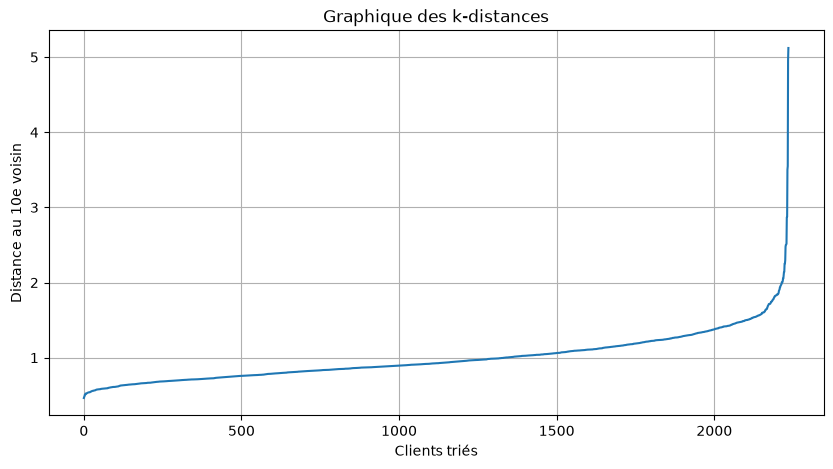

In [27]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

min_samples = 10  # règle courante : 2 × nombre de dimensions (5 composantes)

# Distance de chaque client à son 10e plus proche voisin, triée
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_pca5)
distances, _ = nn.kneighbors(X_pca5)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_dist)
plt.xlabel("Clients triés")
plt.ylabel(f"Distance au {min_samples}e voisin")
plt.title("Graphique des k-distances")
plt.grid(True)
plt.show()

In [28]:
# Effet d'eps sur le nombre de segments et la quantité de bruit
for eps in [0.8, 1.0, 1.3, 1.7, 2.0]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pca5)
    n_segments = len(set(labels)) - (1 if -1 in labels else 0)  # -1 = bruit, ce n'est pas un segment
    n_bruit = (labels == -1).sum()
    tailles = pd.Series(labels[labels != -1]).value_counts().tolist()
    print(f"eps={eps} : {n_segments} segment(s), bruit = {n_bruit} ({n_bruit / len(labels):.0%}), tailles = {tailles}")

eps=0.8 : 11 segment(s), bruit = 1086 (49%), tailles = [673, 322, 54, 23, 18, 16, 11, 10, 8, 8, 7]
eps=1.0 : 6 segment(s), bruit = 472 (21%), tailles = [1529, 193, 14, 11, 10, 7]
eps=1.3 : 1 segment(s), bruit = 89 (4%), tailles = [2147]
eps=1.7 : 1 segment(s), bruit = 15 (1%), tailles = [2221]
eps=2.0 : 1 segment(s), bruit = 7 (0%), tailles = [2229]


In [29]:
# eps retenu : coude du graphique des k-distances
df["Segment_DBSCAN"] = DBSCAN(eps=1.7, min_samples=min_samples).fit_predict(X_pca5)
print(df["Segment_DBSCAN"].value_counts().sort_index())

# Le silhouette exige au moins 2 segments (hors bruit)
masque = df["Segment_DBSCAN"] != -1
if df.loc[masque, "Segment_DBSCAN"].nunique() > 1:
    print("Silhouette (hors bruit) :",
          round(silhouette_score(X_pca5[masque], df.loc[masque, "Segment_DBSCAN"]), 3))
else:
    print("Un seul segment : le silhouette n'est pas calculable.")

Segment_DBSCAN
-1      15
 0    2221
Name: count, dtype: int64
Un seul segment : le silhouette n'est pas calculable.


In [30]:
# Clients étiquetés comme bruit par DBSCAN
atypiques = df[df["Segment_DBSCAN"] == -1]
atypiques[["Depenses_totales", "NumDealsPurchases", "NumWebVisitsMonth",
           "NumCatalogPurchases", "Campagnes_acceptees", "Segment_KMeans"]]

,Depenses_totales,NumDealsPurchases,NumWebVisitsMonth,NumCatalogPurchases,Campagnes_acceptees,Segment_KMeans
9,49,1,20,0,1,0
543,1919,1,3,6,3,1
655,6,0,0,0,0,0
774,137,0,20,0,0,0
870,1727,1,3,7,2,1
917,1919,1,3,6,3,1
981,6,0,14,0,0,0
1042,178,15,19,1,0,2
1187,1020,1,4,6,1,2
1245,8,15,20,0,0,0


### Conclusions 
- **Choix des paramètres :** `min_samples = 10` (2 × nombre de dimensions) ; graphique des k-distances avec un coude autour de **eps ≈ 1,7**.
- **Forme du graphique des k-distances :** montée progressive, sans palier. La densité diminue graduellement du cœur à la périphérie du nuage, sans rupture.
- **Effet d'eps :**
  - eps = 0,8 : 11 segments, dont 9 de moins de 55 clients, et 49 % de bruit (fragmentation) ;
  - eps = 1,0 : un segment dominant (1 529 clients), 5 petits segments, 21 % de bruit ;
  - eps ≥ 1,3 : **un seul segment**, avec un bruit de 4 % à moins de 1 %.
  - Aucune valeur d'eps ne produit une segmentation exploitable.
- **Explication :** DBSCAN définit un segment comme une zone dense séparée par des zones peu denses. Le nuage forme une arche continue sans vide : soit la périphérie passe en bruit et le cœur se fragmente, soit tout fusionne de proche en proche.
- **Enseignement :** DBSCAN confirme l'absence de groupes naturellement séparés. Les segments de KMeans et de la CAH sont un découpage utile d'un continuum, pas des groupes « naturels ».
- **Usage retenu :** détection de clients atypiques. Avec eps = 1,7, DBSCAN isole **15 clients (1 %)** : [ta description de leurs comportements].
- **DBSCAN n'est pas retenu pour la segmentation.**

# X - Comparaison des modèles et stabilité
Objectif : choisir la segmentation finale de façon justifiée, à partir de trois éléments :
1. **des métriques internes**, qui mesurent la qualité géométrique des segments ;
2. **la stabilité**, c'est-à-dire si les segments restent les mêmes quand on perturbe l'algorithme ou les données ;
3. **la robustesse aux choix de préparation** : PCA ou non, avec ou sans `Recency`.

La stabilité est essentielle pour un usage marketing : un client doit changer de segment parce que son comportement change, pas à cause du hasard de l'algorithme.

## 1. Métriques internes
- **Silhouette** (de -1 à 1, plus haut = mieux) : chaque client est-il plus proche de son segment que du segment voisin ?
- **Davies-Bouldin** (≥ 0, plus bas = mieux) : rapport entre la dispersion à l'intérieur des segments et la distance entre segments.
- **Calinski-Harabasz** (≥ 0, plus haut = mieux) : rapport entre la variance *entre* segments et la variance *à l'intérieur* des segments.

DBSCAN est exclu de cette comparaison : il produit un seul segment pour les valeurs d'eps raisonnables, et ces métriques demandent au moins deux segments.

In [31]:
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

def evaluer(X, labels, nom):
    """Calcule les trois métriques internes pour une segmentation donnée."""
    return {
        "Modèle": nom,
        "Silhouette (↑)": silhouette_score(X, labels),
        "Davies-Bouldin (↓)": davies_bouldin_score(X, labels),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X, labels),
    }

resultats = []
for k in [3, 4]:
    # KMeans avec k segments
    labels_km = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_pca5)
    resultats.append(evaluer(X_pca5, labels_km, f"KMeans k={k}"))

    # CAH (Ward) avec k segments
    labels_cah = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_pca5)
    resultats.append(evaluer(X_pca5, labels_cah, f"CAH k={k}"))

tableau_metriques = pd.DataFrame(resultats).set_index("Modèle").round(3)
tableau_metriques

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
Modèle,,,
KMeans k=3,0.314,1.267,1549.413
CAH k=3,0.290,1.305,1425.598
KMeans k=4,0.282,1.353,1251.637
CAH k=4,0.247,1.696,1095.848


## 2. Stabilité de KMeans
Pour comparer deux segmentations, on utilise l'**indice de Rand ajusté (ARI)** :
- **1** : les deux segmentations regroupent exactement les mêmes clients ensemble (peu importe les numéros de segments) ;
- **0** : l'accord n'est pas meilleur que le hasard.

Deux tests :
- **Sensibilité à l'initialisation :** on relance KMeans avec 20 graines aléatoires différentes et une seule initialisation (`n_init=1`), pour voir le comportement « brut » de l'algorithme.
- **Stabilité aux données (bootstrap) :** on entraîne KMeans 20 fois sur 80 % des clients tirés au hasard, puis on affecte tous les clients. Si les segments sont solides, ils doivent réapparaître quel que soit l'échantillon.

In [32]:
def stabilite_initialisation(X, k, n_essais=20):
    """ARI entre une segmentation de référence et des KMeans à initialisation unique."""
    ref = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores = []
    for seed in range(n_essais):
        labels = KMeans(n_clusters=k, n_init=1, random_state=seed).fit_predict(X)
        scores.append(adjusted_rand_score(ref, labels))
    return np.array(scores)


def stabilite_bootstrap(X, k, n_essais=20, part=0.8):
    """ARI entre la référence et des KMeans entraînés sur des sous-échantillons."""
    ref = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    rng = np.random.default_rng(42)
    scores = []
    for i in range(n_essais):
        # Tirage de 80 % des clients, sans remise
        idx = rng.choice(len(X), size=int(part * len(X)), replace=False)
        km = KMeans(n_clusters=k, n_init=10, random_state=i).fit(X[idx])
        # Affectation de TOUS les clients avec le modèle entraîné sur l'échantillon
        scores.append(adjusted_rand_score(ref, km.predict(X)))
    return np.array(scores)


for k in [3, 4]:
    ari_init = stabilite_initialisation(X_pca5, k)
    ari_boot = stabilite_bootstrap(X_pca5, k)
    print(f"k={k} | initialisation : ARI moyen = {ari_init.mean():.3f}, min = {ari_init.min():.3f}"
          f" | bootstrap : ARI moyen = {ari_boot.mean():.3f}, min = {ari_boot.min():.3f}")

k=3 | initialisation : ARI moyen = 0.987, min = 0.981 | bootstrap : ARI moyen = 0.985, min = 0.970
k=4 | initialisation : ARI moyen = 0.735, min = 0.455 | bootstrap : ARI moyen = 0.966, min = 0.916


## 3. Robustesse aux choix de préparation
Deux variantes sont comparées à la segmentation de référence (KMeans k=4 sur 5 composantes PCA) :
- **Variante A - sans PCA :** KMeans directement sur les 13 variables standardisées.
- **Variante B - sans `Recency` :** cette variable ne distinguait aucun segment au TICKET-07.

Le silhouette ne peut pas être comparé entre espaces différents (5 composantes vs 13 variables) : les distances n'ont pas la même échelle. On compare donc les segmentations avec l'**ARI**, qui ne regarde que l'appartenance des clients aux segments.

In [33]:
def preparer(features, n_composantes=5):
    """Applique la même préparation que les TICKETS 05-06 à une liste de variables."""
    X_v = df[features].copy()
    # Log uniquement sur les variables asymétriques identifiées au TICKET-05
    cols = [c for c in cols_log if c in features]
    X_v[cols] = np.log1p(X_v[cols])
    X_v = StandardScaler().fit_transform(X_v)
    if n_composantes is None:
        return X_v  # pas de PCA
    return PCA(n_components=n_composantes, random_state=42).fit_transform(X_v)


reference = df["Segment_KMeans"].values

# Variante A : 13 variables standardisées, sans PCA
X_A = preparer(features_clustering, n_composantes=None)
labels_A = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_A)
print("Variante A (sans PCA)       : ARI vs référence =", round(adjusted_rand_score(reference, labels_A), 3))

# Variante B : sans Recency, puis PCA à 5 composantes
features_sans_recency = [f for f in features_clustering if f != "Recency"]
X_B = preparer(features_sans_recency, n_composantes=5)
labels_B = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_B)
print("Variante B (sans Recency)   : ARI vs référence =", round(adjusted_rand_score(reference, labels_B), 3))

Variante A (sans PCA)       : ARI vs référence = 0.982
Variante B (sans Recency)   : ARI vs référence = 0.986


In [34]:
# Correspondance détaillée entre la référence et chaque variante
print("Référence (lignes) vs Variante A (colonnes)")
display(pd.crosstab(reference, labels_A))

print("Référence (lignes) vs Variante B (colonnes)")
display(pd.crosstab(reference, labels_B))

Référence (lignes) vs Variante A (colonnes)


col_0,0,1,2,3
row_0,,,,
0,837,0,1,0
1,0,307,2,0
2,4,0,513,5
3,0,3,2,562


Référence (lignes) vs Variante B (colonnes)


col_0,0,1,2,3
row_0,,,,
0,837,0,1,0
1,0,0,2,307
2,5,2,515,0
3,0,565,1,1


### Conclusions 
- **Métriques internes :** les trois métriques classent KMeans k=3 premier (silhouette 0,314, Davies-Bouldin 1,267, Calinski-Harabasz 1 549), devant CAH k=3, KMeans k=4 (0,282 / 1,353 / 1 252) et CAH k=4. À k égal, **KMeans surpasse toujours la CAH**.
  - Ces métriques favorisent systématiquement un petit nombre de segments sur des données en continuum (silhouette maximal à k=2 au TICKET-07). L'écart entre k=3 et k=4 est modeste et ne suffit pas à trancher.
- **Stabilité (ARI) :**
  - k=3 : 0,987 avec une seule initialisation ; 0,985 en moyenne (minimum 0,970) en bootstrap.
  - k=4 : **0,735 avec une seule initialisation (minimum 0,455)**, mais 0,966 en moyenne (minimum 0,916) en bootstrap avec `n_init=10`.
  - Pour k=4, KMeans tombe souvent dans des minimums locaux avec une seule initialisation : plusieurs découpages en 4 sont de qualité proche. Avec 10 initialisations, la segmentation devient reproductible. **`n_init ≥ 10` est indispensable.**
  - k=3 capte la structure la plus forte des données ; le 4e segment correspond à une distinction réelle mais plus fine.
- **Robustesse à la préparation :**
  - **Sans PCA :** ARI de 0,982 avec la référence. La PCA ne modifie pas la segmentation ; elle reste utile pour la visualisation et l'interprétation.
  - **Sans `Recency` :** ARI de 0,986. `Recency` n'apporte aucune information à la segmentation ; par parcimonie, elle pourrait être retirée. La référence est conservée et ce constat documenté.
- **Décision finale :** **KMeans k=4** sur 5 composantes PCA, avec `n_init=10` et `random_state=42`. Les métriques favorisent légèrement k=3, mais k=4 est stable avec cette procédure et isole le segment premium réceptif aux campagnes, l'information la plus utile pour le marketing. La CAH et DBSCAN ne sont pas retenus.

# XI - Visualisation des segments
Objectif : rendre les segments compréhensibles d'un coup d'œil, pour une équipe marketing qui ne connaît pas la PCA.
1. Nommer les segments.
2. Visualiser leur taille.
3. Les situer dans l'espace PCA.
4. Comparer leurs comportements variable par variable.

## 1. Nommer les segments
Les numéros de KMeans sont arbitraires. On leur associe un nom métier, **après vérification** du tableau des moyennes : avec `random_state=42`, la numérotation devrait être la même qu'au VII, mais il faut le contrôler à chaque nouvelle exécution.

In [36]:
# Vérification : les moyennes doivent correspondre aux profils du TICKET-07
verif = df.groupby("Segment_KMeans")[["Depenses_totales", "NumDealsPurchases",
                                      "Campagnes_acceptees"]].mean().round(1)
display(verif)

# Correspondance numéro → nom métier (à ajuster si le tableau ci-dessus a changé)
noms_segments = {
    0: "Petits acheteurs",
    1: "Premium engagés",
    2: "Chasseurs de promos",
    3: "Gros acheteurs autonomes",
}
df["Segment"] = df["Segment_KMeans"].map(noms_segments)

# Ordre d'affichage logique : du plus petit au plus gros acheteur
ordre = ["Petits acheteurs", "Chasseurs de promos",
         "Gros acheteurs autonomes", "Premium engagés"]

# Une couleur fixe par segment, réutilisée dans tous les graphiques
palette = dict(zip(ordre, ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]))

,Depenses_totales,NumDealsPurchases,Campagnes_acceptees
Segment_KMeans,,,
0,69.5,1.7,0.1
1,1519.0,1.1,2.0
2,497.9,4.1,0.5
3,1000.9,2.2,0.0


## 2. Taille des segments

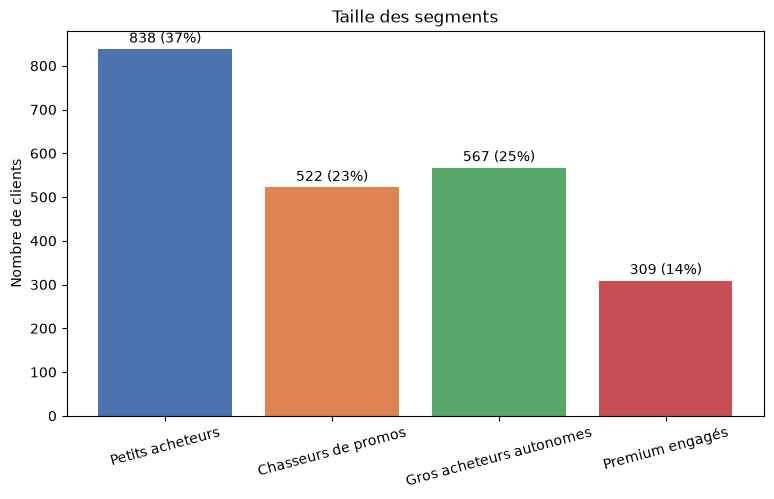

In [37]:
tailles = df["Segment"].value_counts().reindex(ordre)

plt.figure(figsize=(9, 5))
barres = plt.bar(tailles.index, tailles.values, color=[palette[s] for s in ordre])

# Afficher le nombre et le pourcentage au-dessus de chaque barre
for barre, n in zip(barres, tailles.values):
    plt.text(barre.get_x() + barre.get_width() / 2, n + 15,
             f"{n} ({n / len(df):.0%})", ha="center")

plt.ylabel("Nombre de clients")
plt.title("Taille des segments")
plt.xticks(rotation=15)
plt.show()

## 3. Les segments dans l'espace PCA
Deux projections : PC1 × PC2 (niveau d'achat × chasse aux promos) et PC1 × PC3 (niveau d'achat × désengagement). Les deux segments de gros acheteurs se chevauchent sur la première et se séparent sur la seconde.

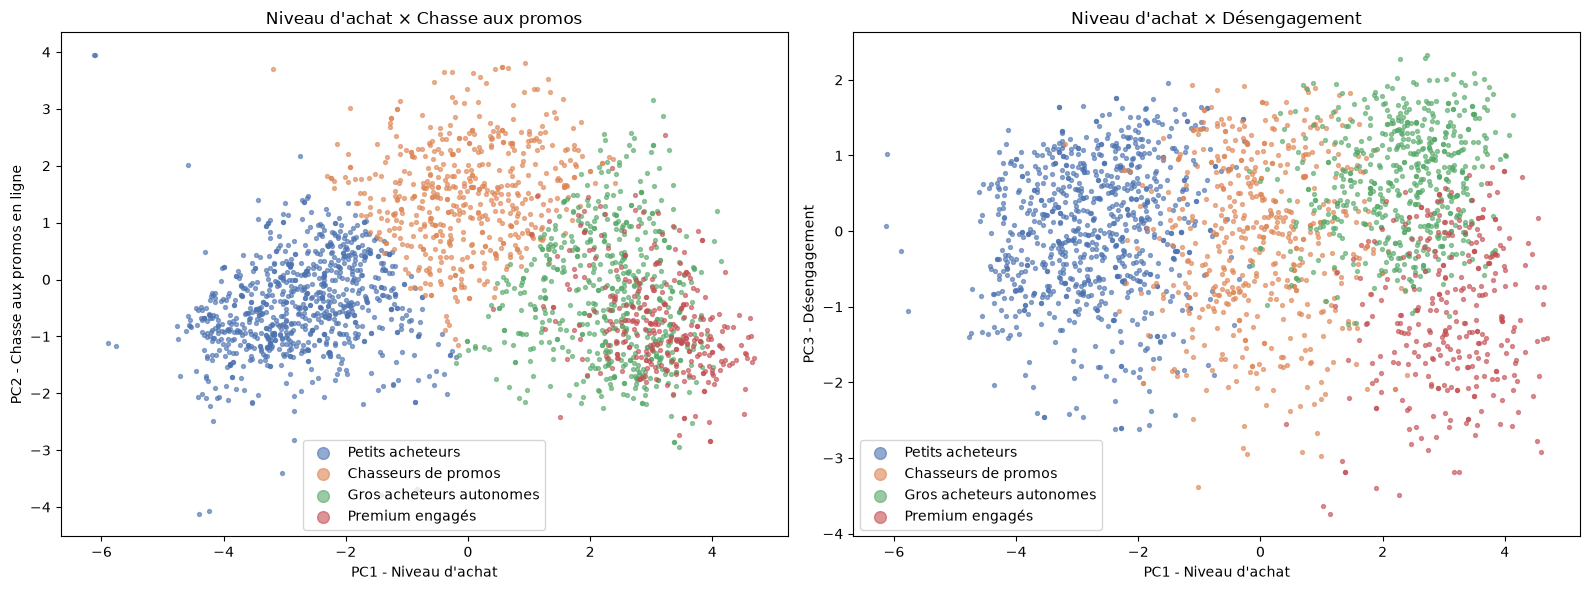

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
projections = [(1, "PC2 - Chasse aux promos en ligne"),
               (2, "PC3 - Désengagement")]

for ax, (j, titre_y) in zip(axes, projections):
    for nom in ordre:
        masque = (df["Segment"] == nom).values  # tableau booléen aligné sur X_pca5
        ax.scatter(X_pca5[masque, 0], X_pca5[masque, j],
                   s=8, alpha=0.6, color=palette[nom], label=nom)
    ax.set_xlabel("PC1 - Niveau d'achat")
    ax.set_ylabel(titre_y)
    ax.legend(markerscale=3)

axes[0].set_title("Niveau d'achat × Chasse aux promos")
axes[1].set_title("Niveau d'achat × Désengagement")
plt.tight_layout()
plt.show()

## 4. Comparaison des comportements
**Heatmap des écarts à la moyenne :** pour chaque segment, la moyenne de chaque variable standardisée (après log). 0 = comportement moyen de l'ensemble des clients ; +1 = un écart-type au-dessus ; -1 = un écart-type en dessous. Cela permet de comparer des variables d'unités différentes (des montants, des nombres d'achats, des jours) sur une même échelle.

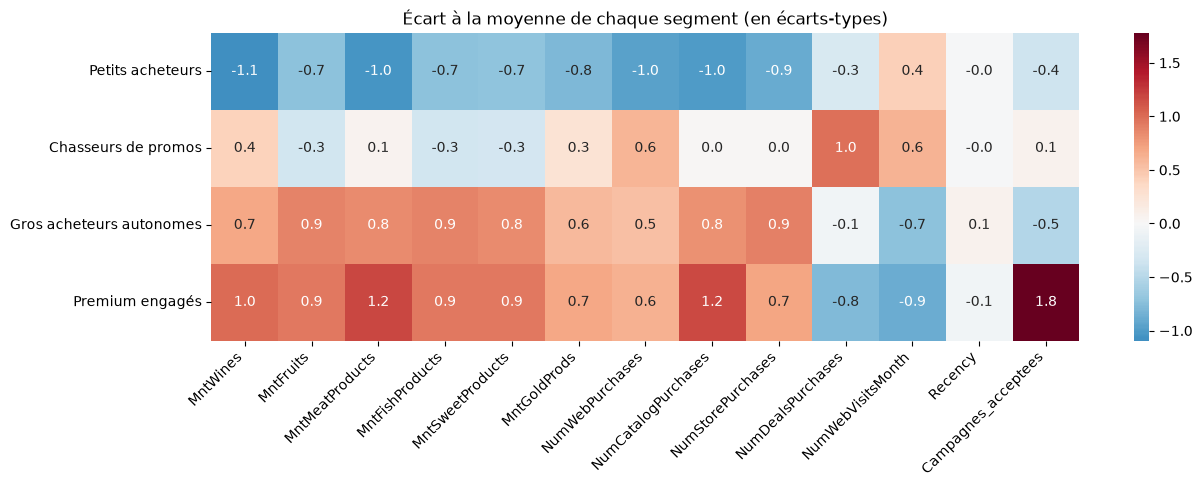

In [40]:
# Moyenne des variables standardisées (X_scaled du TICKET-05) par segment
profil_z = X_scaled.groupby(df["Segment"]).mean().reindex(ordre)

plt.figure(figsize=(14, 4))
sns.heatmap(profil_z, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Écart à la moyenne de chaque segment (en écarts-types)")
plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.show()

**Distributions des variables clés :** les moyennes cachent la dispersion. Les boîtes à moustaches montrent si un segment est homogène (boîte étroite) ou hétérogène (boîte large).

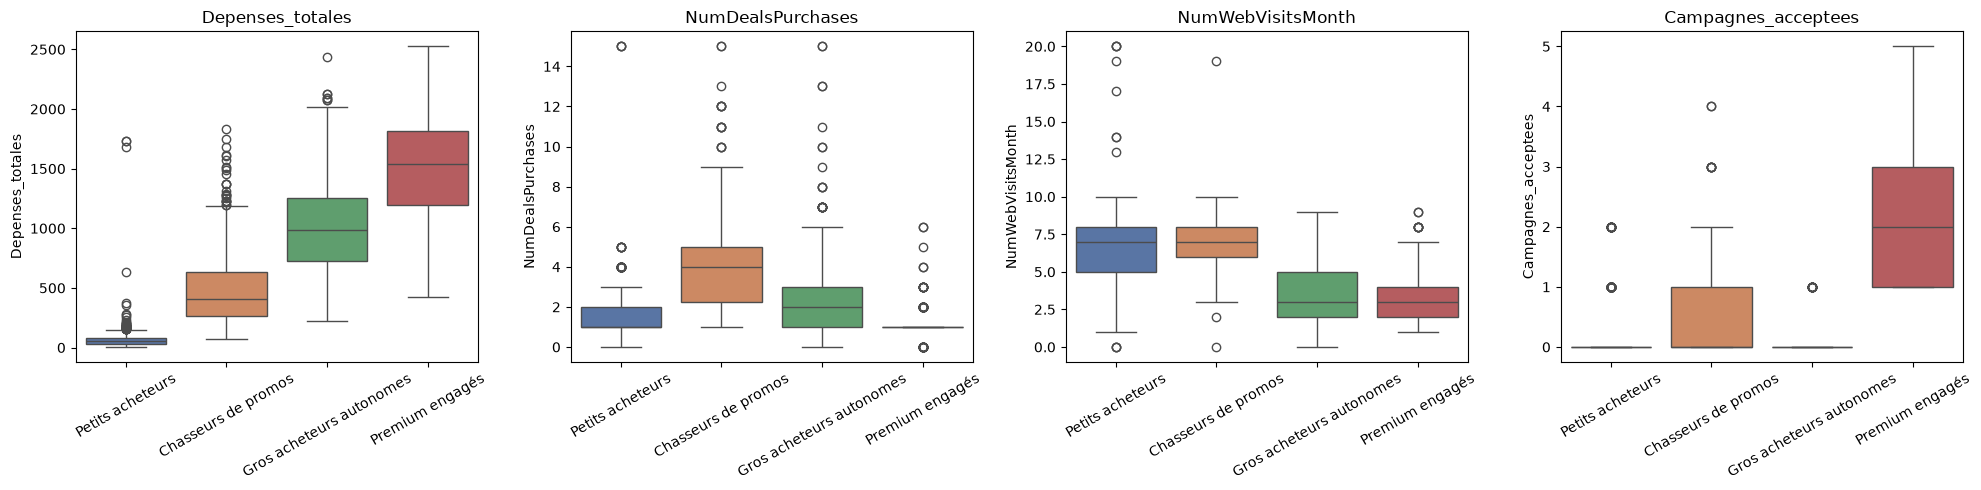

In [41]:
variables_cles = ["Depenses_totales", "NumDealsPurchases",
                  "NumWebVisitsMonth", "Campagnes_acceptees"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, var in zip(axes, variables_cles):
    sns.boxplot(data=df, x="Segment", y=var, order=ordre,
                hue="Segment", palette=palette, legend=False, ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Conclusions 
- **Segments nommés :** Petits acheteurs (37 %), Chasseurs de promos (23 %), Gros acheteurs autonomes (25 %), Premium engagés (14 %).
- **Heatmap des écarts à la moyenne (en écarts-types) :**
  - **Petits acheteurs :** dépenses et achats autour de -1 ; seule valeur positive, les visites web (+0,4). Ils regardent beaucoup et achètent peu.
  - **Chasseurs de promos :** achats en promotion les plus élevés (+1,0), visites et achats web (+0,6). Panier orienté vin et or plutôt que produits frais.
  - **Gros acheteurs autonomes :** dépenses élevées (+0,6 à +0,9), **canal magasin dominant (+0,9)**, peu de visites web (-0,7), réceptivité aux campagnes inférieure à la moyenne (-0,5).
  - **Premium engagés :** viande (+1,2), vin (+1,0), **canal catalogue dominant (+1,2)**, peu de promotions (-0,8), **forte réceptivité aux campagnes (+1,8)**.
  - Les deux segments de gros acheteurs se distinguent par la réceptivité aux campagnes **et par le canal** (magasin vs catalogue).
  - `Recency` est proche de 0 pour tous les segments.
- **Boîtes à moustaches :**
  - Les petits acheteurs sont très homogènes, à l'exception de quelques clients atypiques à forte dépense.
  - Les segments de gros acheteurs sont les plus hétérogènes en dépenses (premium : ~400 à ~2 500). Les offres devront être modulées selon le niveau de dépense à l'intérieur de ces segments.
  - Les premium engagés ont accepté entre 1 et 3 campagnes (médiane 2) ; les autres segments, presque aucune.
- **Communication :** pour une audience métier, privilégier les tailles de segments et des indicateurs en unités réelles ; la projection PCA reste un outil d'analyse interne.

# XII - Profilage client et recommandations marketing
Objectif : décrire chaque segment de façon complète et actionnable.
1. **Qui sont-ils ?** Variables socio-démographiques, qui n'ont pas servi au clustering : leur différence entre segments valide la pertinence de la segmentation.
2. **Qu'achètent-ils ?** Part de chaque catégorie de produits dans leurs dépenses.
3. **Comment achètent-ils ?** Part de chaque canal dans leurs achats.
4. **Comment réagissent-ils au marketing ?** Taux d'acceptation de chaque campagne.
5. Synthèse en **personas** et **recommandations**.

## 1. Profil socio-démographique
On utilise la **médiane** pour le revenu (robuste aux valeurs extrêmes) et la moyenne pour les autres variables.

In [42]:
profil_demo = df.groupby("Segment").agg(
    Clients=("Segment", "size"),
    Age_moyen=("Age", "mean"),
    Revenu_median=("Income", "median"),
    Enfants_jeunes=("Kidhome", "mean"),      # enfants en bas âge
    Adolescents=("Teenhome", "mean"),
    Part_parents=("Est_parent", "mean"),     # proportion de clients avec au moins un enfant
    Taille_foyer=("Taille_foyer", "mean"),
    Anciennete_mois=("Anciennete_mois", "mean"),
).reindex(ordre).round(2)

profil_demo

,Clients,Age_moyen,Revenu_median,Enfants_jeunes,Adolescents,Part_parents,Taille_foyer,Anciennete_mois
Segment,,,,,,,,
Petits acheteurs,838,42.34,32922.0,0.80,0.44,0.88,2.89,9.65
Chasseurs de promos,522,47.04,49973.5,0.49,0.79,0.94,2.94,13.52
Gros acheteurs autonomes,567,46.89,67893.0,0.10,0.54,0.57,2.30,11.58
Premium engagés,309,46.04,79205.0,0.04,0.14,0.17,1.76,11.65


In [48]:
# Répartition des niveaux d'éducation et des situations familiales dans chaque segment
# normalize="index" : chaque ligne totalise 100 %
print("Éducation (part des clients de chaque segment)")
display(pd.crosstab(df["Segment"], df["Education"], normalize="index").reindex(ordre).round(2))

print("Situation familiale (part des clients de chaque segment)")
display(pd.crosstab(df["Segment"], df["Marital_Status"], normalize="index").reindex(ordre).round(2))

Éducation (part des clients de chaque segment)


Education,Licence,Postgrad,Premier cycle
Segment,,,
Petits acheteurs,0.48,0.35,0.17
Chasseurs de promos,0.48,0.46,0.06
Gros acheteurs autonomes,0.54,0.37,0.10
Premium engagés,0.54,0.38,0.08


Situation familiale (part des clients de chaque segment)


Marital_Status,En couple,Seul
Segment,,
Petits acheteurs,0.65,0.35
Chasseurs de promos,0.66,0.34
Gros acheteurs autonomes,0.66,0.34
Premium engagés,0.58,0.42


## 2. Panier : part de chaque catégorie dans les dépenses
On travaille en **proportions** plutôt qu'en montants : un petit acheteur dépense moins partout, mais son panier peut avoir une composition très différente de celle d'un gros acheteur.

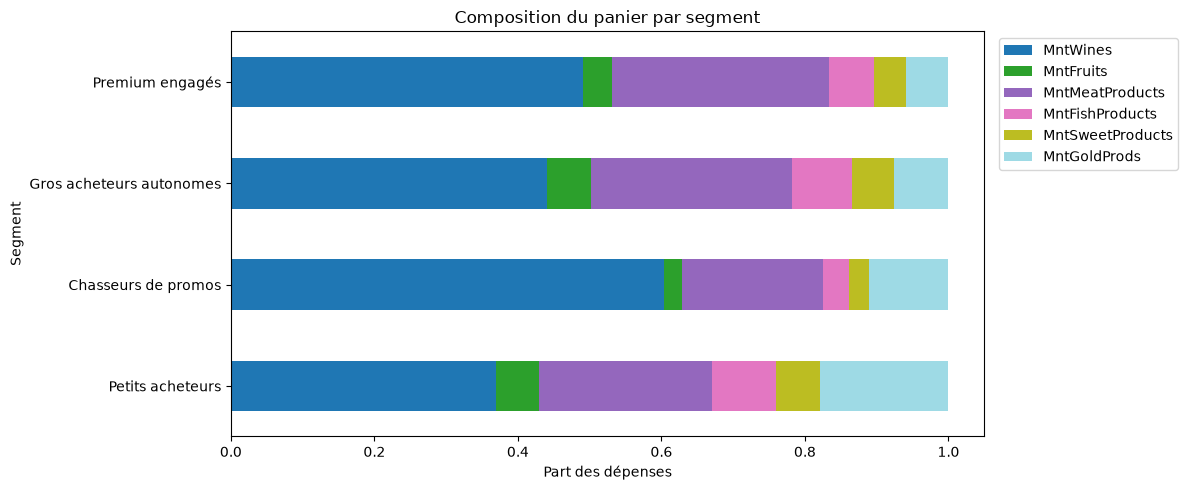

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Segment,,,,,,
Petits acheteurs,0.37,0.06,0.24,0.09,0.06,0.18
Chasseurs de promos,0.60,0.02,0.20,0.04,0.03,0.11
Gros acheteurs autonomes,0.44,0.06,0.28,0.08,0.06,0.08
Premium engagés,0.49,0.04,0.30,0.06,0.04,0.06


In [44]:
# Part de chaque catégorie dans les dépenses totales de chaque client
part_categories = df[cols_depenses].div(df["Depenses_totales"], axis=0)

# Moyenne de ces parts par segment
panier = part_categories.groupby(df["Segment"]).mean().reindex(ordre)

panier.plot(kind="barh", stacked=True, figsize=(12, 5), colormap="tab20")
plt.xlabel("Part des dépenses")
plt.title("Composition du panier par segment")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

panier.round(2)

## 3. Canaux : part de chaque canal dans les achats

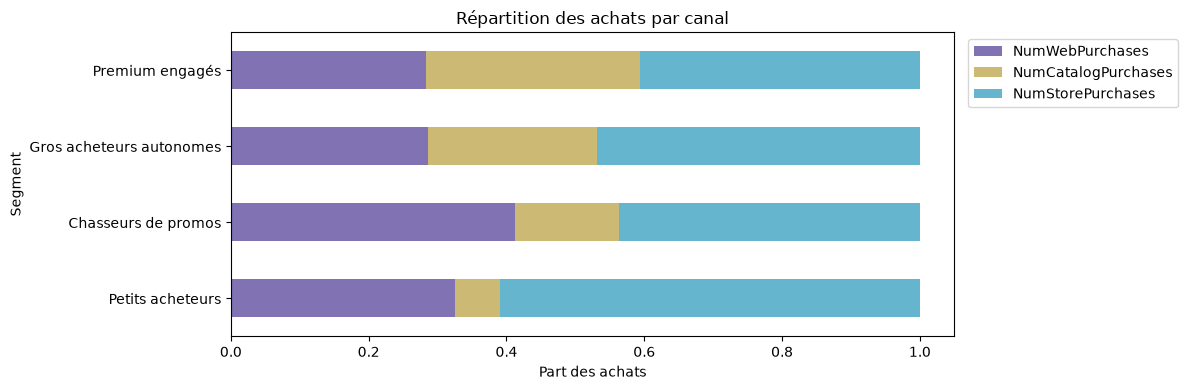

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
Segment,,,
Petits acheteurs,0.33,0.06,0.61
Chasseurs de promos,0.41,0.15,0.44
Gros acheteurs autonomes,0.29,0.25,0.47
Premium engagés,0.28,0.31,0.41


In [45]:
# Les clients sans aucun achat donneraient une division par 0 : on les met à NaN (ignorés dans la moyenne)
achats_non_nuls = df["Achats_totaux"].replace(0, np.nan)
part_canaux = df[cols_achats].div(achats_non_nuls, axis=0)

canaux = part_canaux.groupby(df["Segment"]).mean().reindex(ordre)

canaux.plot(kind="barh", stacked=True, figsize=(12, 4),
            color=["#8172B3", "#CCB974", "#64B5CD"])
plt.xlabel("Part des achats")
plt.title("Répartition des achats par canal")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

canaux.round(2)

## 4. Réaction aux campagnes
Taux d'acceptation de chaque campagne par segment : `Response` est la dernière campagne, `AcceptedCmp1` à `AcceptedCmp5` les précédentes.

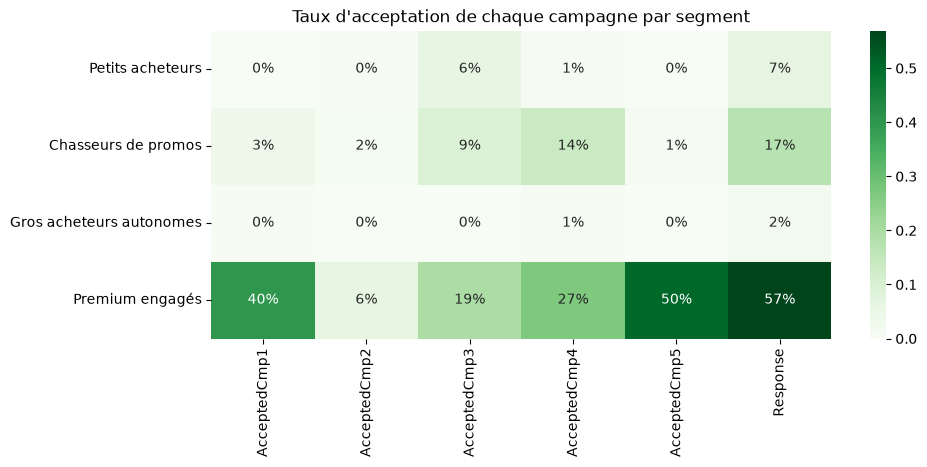

In [46]:
# Moyenne d'une variable 0/1 = taux d'acceptation
taux_campagnes = df.groupby("Segment")[cols_campagnes].mean().reindex(ordre)

plt.figure(figsize=(10, 4))
sns.heatmap(taux_campagnes, annot=True, fmt=".0%", cmap="Greens")
plt.title("Taux d'acceptation de chaque campagne par segment")
plt.ylabel("")
plt.show()

In [47]:
# Poids de chaque segment : en nombre de clients et en chiffre d'affaires
poids = pd.DataFrame({
    "Part des clients": df["Segment"].value_counts(normalize=True),
    "Part du CA": df.groupby("Segment")["Depenses_totales"].sum() / df["Depenses_totales"].sum(),
}).reindex(ordre).round(3)
poids

,Part des clients,Part du CA
Segment,,
Petits acheteurs,0.375,0.043
Chasseurs de promos,0.233,0.192
Gros acheteurs autonomes,0.254,0.419
Premium engagés,0.138,0.346


## 5. Personas et recommandations

### Petits acheteurs - 37 % des clients, ≈ 4 % du CA
- **Qui :** les plus jeunes (42 ans en moyenne), revenu médian le plus faible (≈ 33 k\$), **88 % de parents**, surtout d'enfants en bas âge. **Clients les plus récents** (≈ 10 mois d'ancienneté). Part la plus élevée de diplômés de premier cycle (17 %).
- **Quoi et comment :** dépenses très faibles (≈ 70 \$ sur 2 ans). Panier : vin (37 %), viande (24 %) et la plus forte part de produits en or (18 %). Achètent surtout **en magasin (61 %)**, presque jamais par catalogue (6 %). Visitent souvent le site (6,4 visites/mois) sans y acheter beaucoup.
- **Marketing :** quasi insensibles aux campagnes (7 % au maximum, pour la dernière).
- **Recommandation :** ne pas investir dans des campagnes coûteuses (catalogue, campagnes générales). Miser sur des **leviers numériques peu coûteux** pour convertir leur trafic web : offres en ligne ciblées sur les besoins des jeunes familles, programme de fidélité d'entrée de gamme. Comme ce sont de nouveaux clients, l'enjeu est de les faire monter en valeur dans le temps.

### Chasseurs de promos - 23 % des clients, ≈ 19 % du CA
- **Qui :** 47 ans, revenu médian intermédiaire (≈ 50 k\$), **94 % de parents** (la plus forte proportion), surtout d'**adolescents**, et les foyers les plus grands (2,9 personnes). **Clients les plus anciens** (≈ 14 mois) et la plus forte part de diplômés de cycles supérieurs (46 %).
- **Quoi et comment :** dépenses moyennes (≈ 500 \$). **Le vin représente 60 % de leur panier**, la plus forte part de tous les segments. Champions des **achats en promotion** (4,1) et du **web** (41 % de leurs achats, plus haute part).
- **Marketing :** réceptivité modérée, surtout à la dernière campagne (17 %) et à la campagne 4 (14 %).
- **Recommandation :** campagnes **web et courriel** centrées sur le vin, inspirées de la campagne 4 et de la dernière. Préférer des **promotions conditionnelles** (lots, seuils d'achat) aux remises générales, pour augmenter le panier sans sacrifier la marge. Leur ancienneté en fait une base fidèle à entretenir.

### Gros acheteurs autonomes - 25 % des clients, ≈ 42 % du CA
- **Qui :** 47 ans, revenu élevé (≈ 68 k\$), **57 % de parents**, presque uniquement d'adolescents, foyers de 2,3 personnes.
- **Quoi et comment :** fortes dépenses (≈ 1 000 \$). Panier : vin (44 %) et viande (28 %). **Canal magasin dominant** (47 %), peu de visites web.
- **Marketing :** **imperméables aux campagnes actuelles** (2 % au maximum).
- **Recommandation :** c'est le **segment qui pèse le plus dans le chiffre d'affaires**, mais les campagnes actuelles y sont du budget gaspillé. Deux actions : réduire les sollicitations inefficaces, et **tester de nouveaux formats** par A/B testing, plutôt orientés vers l'expérience en magasin (fidélité en caisse, dégustations, service). Priorité : **protéger la relation**, car perdre ces clients coûterait cher.

### Premium engagés - 14 % des clients, ≈ 35 % du CA
- **Qui :** 46 ans, **revenu le plus élevé** (≈ 79 k\$), **rarement parents** (17 %), **les plus petits foyers** (1,8 personne), plus souvent seuls (42 %).
- **Quoi et comment :** **dépenses les plus élevées** (≈ 1 500 \$). Panier : vin (49 %) et viande (30 %). **Canal catalogue le plus fort** (31 %), peu de promotions.
- **Marketing :** **seuls réellement réceptifs** : 57 % à la dernière campagne, 50 % à la campagne 5, 40 % à la campagne 1.
- **Recommandation :** **segment prioritaire** des campagnes. Reproduire les formats des campagnes 5, 1 et de la dernière ; catalogue premium centré sur le vin et la viande. Miser sur **l'exclusivité plutôt que le prix** (offres VIP, avant-premières, sélections haut de gamme), puisqu'ils utilisent peu les promotions. Adapter la valeur des offres au niveau de dépense, car le segment est hétérogène.

### Constat transversal
La **campagne 2** a échoué partout (6 % au maximum, même chez les premium) : à ne pas reproduire.

### Conclusions
- - **Validation externe :** les variables socio-démographiques, absentes du clustering, diffèrent nettement entre segments (revenu médian de 33k à 79k, part de parents de 94 % à 17 %). Les segments correspondent à de vraies populations de clients. L'éducation et la situation familiale varient peu.
- **Concentration de la valeur :** les gros acheteurs autonomes et les premium engagés représentent 39 % des clients mais ≈ 77 % du chiffre d'affaires ; les petits acheteurs, 37 % des clients pour ≈ 4 %.
- **Efficacité marketing :** les campagnes actuelles ne fonctionnent réellement que sur le segment premium (jusqu'à 57 % d'acceptation). Le segment autonome, le plus important en chiffre d'affaires, n'y répond pas (≤ 2 %). La campagne 2 a échoué sur tous les segments.
- **Priorités recommandées :**
  1. **Premium engagés :** concentrer les campagnes, miser sur l'exclusivité et le catalogue.
  2. **Gros acheteurs autonomes :** arrêter les sollicitations inefficaces et tester de nouveaux formats orientés magasin par A/B testing.
  3. **Chasseurs de promos :** promotions conditionnelles sur le vin, par le web et le courriel.
  4. **Petits acheteurs :** leviers numériques à faible coût pour faire monter en valeur ces clients récents.
- **Limites :**
  - les segments découpent un continuum : un client proche d'une frontière peut basculer d'un segment à l'autre ;
  - les données proviennent d'une seule enseigne sur 2 ans et doivent être mises à jour régulièrement ;
  - les recommandations sont des hypothèses à valider par des tests (A/B testing) avant un déploiement à grande échelle.

# XIII- Pipeline réutilisable et sauvegarde du modèle
Objectif : regrouper toute la chaîne de traitement (log, standardisation, PCA, KMeans) dans un **pipeline scikit-learn**, puis le sauvegarder. On pourra ainsi affecter un nouveau client à son segment en une ligne, avec exactement le même référentiel qu'à l'entraînement.

## 1. Construction du pipeline
- `ColumnTransformer` : applique `log1p` uniquement aux variables asymétriques et laisse les autres inchangées.
- `StandardScaler`, `PCA` (5 composantes) puis `KMeans` (k=4, `n_init=10`, `random_state=42`) : les mêmes réglages que dans les tickets précédents.

In [49]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

# Étape 1 : log1p sur les variables asymétriques, les autres passent sans modification
transformation_log = ColumnTransformer(
    transformers=[("log", FunctionTransformer(np.log1p), cols_log)],
    remainder="passthrough",
)

# Chaîne complète : chaque étape reçoit la sortie de la précédente
pipeline_segmentation = Pipeline([
    ("log", transformation_log),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=5, random_state=42)),
    ("kmeans", KMeans(n_clusters=4, n_init=10, random_state=42)),
])

# Un seul fit, sur les données brutes des 13 variables (avant log et standardisation)
pipeline_segmentation.fit(df[features_clustering])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('log', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['MntWines','MntFruits','MntMeatProducts',...,'NumWebVisitsMonth', 'Recency','Campagnes_acceptees']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

## 2. Vérification
Le pipeline doit reproduire exactement la segmentation des tickets précédents. Les numéros de segments peuvent différer : on compare donc avec l'ARI et le crosstab.

In [50]:
labels_pipeline = pipeline_segmentation.predict(df[features_clustering])

print("ARI pipeline vs segmentation de référence :",
      round(adjusted_rand_score(df["Segment_KMeans"], labels_pipeline), 3))
display(pd.crosstab(df["Segment_KMeans"], labels_pipeline))

ARI pipeline vs segmentation de référence : 1.0


col_0,0,1,2,3
Segment_KMeans,,,,
0,838,0,0,0
1,0,309,0,0
2,0,0,522,0
3,0,0,0,567


In [51]:
# Correspondance entre les numéros du pipeline et les noms métier,
# déduite automatiquement du crosstab (segment le plus fréquent pour chaque numéro)
correspondance = pd.crosstab(labels_pipeline, df["Segment"]).idxmax(axis=1).to_dict()
correspondance

{0: 'Petits acheteurs',
 1: 'Premium engagés',
 2: 'Chasseurs de promos',
 3: 'Gros acheteurs autonomes'}

## 3. Sauvegarde
On sauvegarde le pipeline **avec** la correspondance des noms et la liste des variables attendues : sans elles, le modèle seul serait inutilisable.

In [52]:
import joblib

modele = {
    "pipeline": pipeline_segmentation,
    "noms_segments": correspondance,
    "features": features_clustering,
}
joblib.dump(modele, "../models/segmentation_kmeans.joblib")
print("Modèle sauvegardé.")

Modèle sauvegardé.


## 4. Affecter un nouveau client
On recharge le modèle comme le ferait une autre application, puis on prédit le segment d'un client. Les variables dérivées (ici `Campagnes_acceptees`) doivent être calculées de la même façon qu'au TICKET-03.

In [53]:
def predire_segment(clients, chemin="../models/segmentation_kmeans.joblib"):
    """Affecte un ou plusieurs clients (données brutes) à leur segment."""
    modele = joblib.load(chemin)
    clients = clients.copy()

    # Même feature engineering qu'au TICKET-03
    clients["Campagnes_acceptees"] = clients[cols_campagnes].sum(axis=1)

    # transform + predict uniquement : aucun fit ici
    labels = modele["pipeline"].predict(clients[modele["features"]])
    return pd.Series(labels, index=clients.index).map(modele["noms_segments"])


# Exemple : 5 clients tirés du dataset brut, pour simuler de nouvelles arrivées
nouveaux_clients = pd.read_csv("../data/marketing_campaign.csv", sep="\t").sample(5, random_state=1)
nouveaux_clients["Segment_prédit"] = predire_segment(nouveaux_clients)
nouveaux_clients[["MntWines", "MntMeatProducts", "NumDealsPurchases",
                  "NumCatalogPurchases", "Segment_prédit"]]

,MntWines,MntMeatProducts,NumDealsPurchases,NumCatalogPurchases,Segment_prédit
779,522,522,2,9,Gros acheteurs autonomes
389,866,151,3,2,Gros acheteurs autonomes
510,127,56,3,2,Chasseurs de promos
1553,292,415,1,5,Premium engagés
1172,863,547,1,2,Gros acheteurs autonomes


### Conclusions 
- **Pipeline scikit-learn** regroupant toute la chaîne : `log1p` sur les 10 variables asymétriques (`ColumnTransformer`), standardisation, PCA à 5 composantes, KMeans (k=4, `n_init=10`, `random_state=42`).
- **Vérification :** ARI de **1,0** avec la segmentation de référence ; le pipeline reproduit exactement les segments, avec la même numérotation.
- **Sauvegarde** (`models/segmentation_kmeans.joblib`) du pipeline, de la correspondance numéro → nom de segment et de la liste des variables attendues.
- **Utilisation :** la fonction `predire_segment` affecte de nouveaux clients avec `predict` uniquement. Aucun `fit` : le référentiel (moyennes, écarts-types, axes, centres) reste celui de l'entraînement, pour que les segments gardent le même sens dans le temps.
- **Limite identifiée :** `Campagnes_acceptees` est calculée hors du pipeline. Toute divergence entre ce calcul et celui de l'entraînement fausserait les prédictions sans erreur visible (training-serving skew). Amélioration possible : intégrer le feature engineering au pipeline via un module Python dédié.

In [54]:
import pandas, numpy, sklearn, matplotlib, seaborn, scipy, joblib

for lib in [pandas, numpy, sklearn, matplotlib, seaborn, scipy, joblib]:
    print(f"{lib.__name__}=={lib.__version__}")

pandas==3.0.3
numpy==2.4.6
sklearn==1.9.0
matplotlib==3.11.0
seaborn==0.13.2
scipy==1.17.1
joblib==1.5.3
